# Independent verification of the metal photo-rates added to the Grackle HM2012 UV background tables

The files `HM2012_metal_test.h5` and `HM2012_shielded_metal_test.h5` extend the stock
Grackle tables (`CloudyData_UVB=HM2012.h5`, `CloudyData_UVB=HM2012_shielded.h5`) with three
new optically-thin photo-rates for the metal network:

| dataset | reaction | threshold |
|---|---|---|
| `/UVBRates/Chemistry/kphCI`   | C I + γ → C II + e⁻ | 11.260 eV (1101 Å) |
| `/UVBRates/Chemistry/kphOI`   | O I + γ → O II + e⁻ | 13.618 eV (910.4 Å) |
| `/UVBRates/Chemistry/kdissCO` | CO + γ → C I + O I  | 11.09 eV nominal; discrete predissociation bands at 912–1080 Å |

They were produced by `scripts/add_metal_UVB_rates.py`. This notebook **verifies those
numbers with an independent calculation**: its own spectrum parser, its own integrator,
and — for C I and O I — an *independent atomic-data source* (Verner et al. 1996 fits),
plus the piecewise fits used in [genchiaki/enzo-dev `Grid_WalkPhotonPackage.C`](https://github.com/genchiaki/enzo-dev/blob/86a851f9cec9683aca454a7db8b77c05bf1c27dc/src/enzo/Grid_WalkPhotonPackage.C#L1164).

**Inputs** (in `verification_data/` unless noted):

- `../UVB.out` — Haardt & Madau (2012, ApJ 746, 125) UV background spectrum
  ("quasars+galaxies", CUBA V6.3): J(λ, z) in erg s⁻¹ cm⁻² Hz⁻¹ sr⁻¹ on 60 redshifts × 575 wavelengths.
- `C.h5`, `O.h5`, `CO.h5` — cross sections from the Leiden photodissociation/photoionisation
  database of Heays, Bosman & van Dishoeck (2017, A&A 602, A105; arXiv:1701.04459), downloaded from
  <https://home.strw.leidenuniv.nl/~ewine/photo/> (`all_cross_sections_h5.zip`).
- `ISRF.dat` — the Draine (1978) interstellar radiation field tabulation from the same site
  (used only to benchmark the integrator against the rates published in the paper).
- `verner_sigma.dat` — total photoionization cross sections of H I, C I, O I tabulated from
  Verner et al. (1996, ApJ 465, 487) / Verner & Yakovlev (1995) by compiling D. Verner's
  reference `phfit2.f` (both Fortran sources included; regenerate with
  `gfortran -std=legacy driver.f phfit2.f && ./a.out`).

**Verification strategy**

1. Recompute the photo-rate integral with independently written code.
2. Validate the machinery against two external anchors:
   the ISRF rates published in Heays et al. (2017) Tables 18–19, and the
   H I photoionization rate `k24` already present in the Grackle table.
3. Compare against the table datasets, and cross-check C I / O I with Verner et al. (1996)
   atomic data and with the enzo-dev fits.

**Verdict (details below):** the table values are correct. The independent
integration with the same Leiden cross sections agrees to <0.3% for z ≲ 5 (worst 1.8%
over z ≈ 6–11, an interpolation-detail regime), and the fully independent Verner
cross sections reproduce kphCI within ~1% and kphOI within ~3% — far inside the
~30% cross-section uncertainty quoted by Heays et al. (2017).
One packaging bug was found: **`HM2012_metal_test.h5` is missing the `kdissCO` dataset**
(only the shielded file has it), so Grackle will silently use k_CO = 0 with that table.

## 1. The physics

For an isotropic radiation field with mean intensity $J_\nu$ (erg s⁻¹ cm⁻² Hz⁻¹ sr⁻¹), the
optically-thin photoionization/photodissociation rate of a species with cross section
$\sigma(\nu)$ is

$$k \;=\; \int_{\nu_{\rm th}}^{\infty} \frac{4\pi J_\nu}{h\nu}\, \sigma(\nu)\, d\nu
\;=\; \frac{4\pi}{h} \int_{\lambda_{\rm min}}^{\lambda_{\rm th}} J(\lambda)\, \sigma(\lambda)\, \frac{d\lambda}{\lambda} \quad [\mathrm{s^{-1}}],$$

where $4\pi J_\nu / h\nu$ is the photon number flux per unit frequency and the second form
(used here) follows from $|d\nu| = c\,d\lambda/\lambda^2$ and $J_\nu \, d\nu = J(\lambda)^{\rm (per\,Hz)} \frac{c}{\lambda^2} d\lambda$
with $J$ kept per-Hz as tabulated in `UVB.out`.

The three channels behave very differently under a UV background:

- **C I (11.26 eV):** the threshold lies *below* the H I Lyman limit (13.598 eV), so the
  rate is dominated by 912–1101 Å photons that stream freely through the IGM. kphCI is
  therefore the largest of the three rates.
- **O I (13.618 eV):** the threshold lies just *above* the Lyman limit, so O I only sees the
  heavily absorbed λ < 910 Å part of the UVB. Because σ_OI *rises* from ~2×10⁻¹⁸ cm² at
  threshold to ~10⁻¹⁷ cm² at 20–50 eV while σ_HI falls as ~E⁻³, kphOI is dominated by the
  hard part of the spectrum — and actually exceeds k24 (see §7).
- **CO (predissociation bands):** CO photodissociation proceeds through discrete
  line absorption into predissociating states between 912 and 1080 Å — there is no
  significant continuum above 912 Å. The Leiden cross section (Visser, van Dishoeck & Black
  2009 band model at T_ex = 100 K, b = 1 km s⁻¹, plus the Chan et al. 1993 continuum) is a
  dense line forest that must be resolved by the integration grid.

In [1]:
import os
import numpy as np
import h5py
import matplotlib.pyplot as plt

# integration helper (np.trapz was renamed in numpy 2.0)
trapz = getattr(np, "trapezoid", None) or np.trapz

# physical constants (CGS)
h_cgs = 6.62607015e-27          # erg s
c_cgs = 2.99792458e10           # cm s^-1
eV    = 1.602176634e-12         # erg
HC_EV_ANG = h_cgs * c_cgs / eV * 1.0e8   # 12398.4 eV*Angstrom

E_TH = {"CI": 11.260, "OI": 13.618, "CO": 11.09}   # eV

DATA   = "verification_data"
REPO   = ".."
TABLES = os.path.join(REPO, "grackle_data_files", "input")

# palette (fixed assignment per species throughout the notebook)
C_CI, C_OI, C_CO, C_REF = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": "#e6e4dd",
    "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "font.size": 10, "legend.frameon": False,
})

## 2. The Haardt & Madau (2012) spectrum

`UVB.out` is the CUBA output distributed by Haardt & Madau: one row of 60 sampling
redshifts (z = 0 … 15.93), then 575 rows of `[λ (Å, rest frame), J(z₀), …, J(z₅₉)]`.
At absorption edges (e.g. the H I Lyman limit) a wavelength appears **twice**, giving J on
either side of the discontinuity; to keep the grid strictly increasing the duplicate is
nudged up by one ULP (no smearing of the edge).

In [2]:
def load_uvb(fname):
    """Parse UVB.out -> (z [Nz], lam [Nlam, Angstrom, strictly increasing],
    J [Nlam, Nz] in erg/s/cm^2/Hz/sr)."""
    vals = []
    with open(fname) as fh:
        for line in fh:
            s = line.strip()
            if not s or s.startswith("#"):
                continue
            vals.append([float(x) for x in s.split()])
    z    = np.array(vals[0])
    body = np.array(vals[1:])
    lam, J = body[:, 0], body[:, 1:]
    assert J.shape[1] == z.size
    idx = np.argsort(lam, kind="stable")      # keep duplicate-edge row order
    lam, J = lam[idx], J[idx]
    for i in range(1, lam.size):
        if lam[i] <= lam[i - 1]:              # duplicated edge wavelength
            lam[i] = np.nextafter(lam[i - 1], np.inf)
    return z, lam, J

z_spec, lam_spec, J = load_uvb(os.path.join(REPO, "UVB.out"))
print(f"{z_spec.size} redshifts: z = {z_spec.min():g} ... {z_spec.max():g}")
print(f"{lam_spec.size} wavelengths: {lam_spec.min():.3g} ... {lam_spec.max():.3g} Angstrom")

60 redshifts: z = 0 ... 15.93
575 wavelengths: 0.000248 ... 1e+05 Angstrom


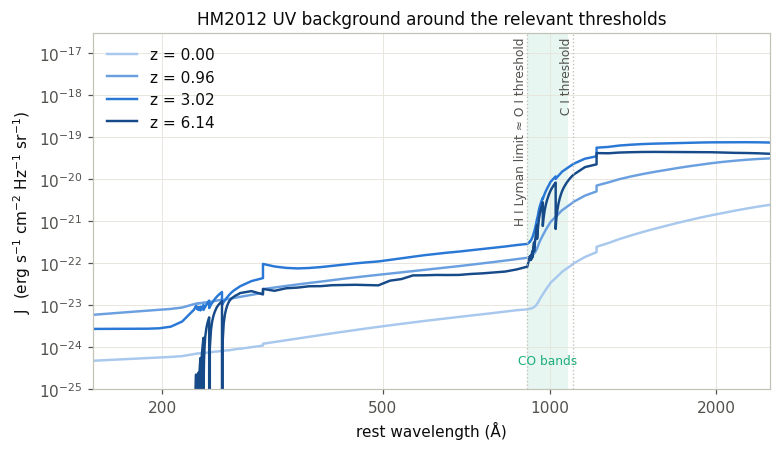

In [3]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
blues = ["#a8c8ee", "#6ba0e0", "#2a78d6", "#174a89"]      # sequential: low z -> high z
for zz, cc in zip((0.0, 1.0, 3.0, 6.0), blues):
    iz = np.argmin(abs(z_spec - zz))
    ax.loglog(lam_spec, J[:, iz], color=cc, lw=1.6, label=f"z = {z_spec[iz]:.2f}")
for x, lab in ((912.0, "H I Lyman limit ≈ O I threshold"),
               (HC_EV_ANG / E_TH["CI"], "C I threshold")):
    ax.axvline(x, color="#c3c2b7", lw=0.9, ls=":")
    ax.text(x, 2.5e-17, " " + lab, rotation=90, va="top", ha="right",
            fontsize=8, color="#52514e")
ax.axvspan(912.0, 1080.0, color=C_CO, alpha=0.10, lw=0)
ax.text(993, 4e-25, "CO bands", ha="center", fontsize=8, color=C_CO)
ax.set(xlim=(150, 2500), ylim=(1e-25, 3e-17),
       xlabel="rest wavelength (Å)",
       ylabel=r"J  (erg s$^{-1}$ cm$^{-2}$ Hz$^{-1}$ sr$^{-1}$)",
       title="HM2012 UV background around the relevant thresholds")
ax.set_xticks([200, 500, 1000, 2000], labels=["200", "500", "1000", "2000"])
ax.minorticks_off()
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

The plot shows why the three rates differ so much: the C I window (912–1101 Å) sits on the
unabsorbed side of the Lyman limit; the O I window (< 910 Å) starts right where the IGM
absorption bites; the CO band region (shaded) coincides with the C I window.

## 3. Cross sections

Three sources are compared:

1. **Leiden database** (what `add_metal_UVB_rates.py` used — Heays et al. 2017):
   C from TOPbase (Opacity Project), O from Mendoza (1996)/TOPbase + Huebner & Mukherjee
   (2015), CO photodissociation from the Visser et al. (2009) line-by-line band model plus
   the Chan et al. (1993) continuum.
2. **Verner et al. (1996)** analytic fits (total = sum over subshells, via the reference
   `phfit2.f` — this is the atomic data used by Cloudy and by stock enzo). *Fully
   independent of the Leiden files.*
3. **enzo-dev (genchiaki fork)** `Grid_WalkPhotonPackage.C` piecewise log₁₀ fits for C I and
   O I, themselves fits *to* the Heays (2017) data, and a constant band-averaged
   σ_CO = 1.74554×10⁻¹⁷ cm².

In [4]:
def load_leiden(species, dataset):
    """Leiden cross-section file -> (lam [Angstrom, increasing], sigma [cm^2])."""
    with h5py.File(os.path.join(DATA, species + ".h5")) as f:
        readme = f["README"][()]
        lam = f["wavelength"][:] * 10.0          # nm -> Angstrom
        sig = f[dataset][:]
    idx = np.argsort(lam, kind="stable")
    lam, sig = lam[idx], sig[idx]
    for i in range(1, lam.size):
        if lam[i] <= lam[i - 1]:
            lam[i] = np.nextafter(lam[i - 1], np.inf)
    txt = readme.decode() if isinstance(readme, bytes) else str(readme)
    print(f"--- {species}: " + txt.replace(chr(92)+"n", " | ")[:150])
    return lam, sig

lamC,  sigC  = load_leiden("C",  "photoionisation")
lamO,  sigO  = load_leiden("O",  "photoionisation")
lamCO, sigCO = load_leiden("CO", "photodissociation")

for name, l, s in (("C", lamC, sigC), ("O", lamO, sigO), ("CO", lamCO, sigCO)):
    lmax = l[s > 0].max()
    print(f"{name:>3}: {l.size} points, sigma > 0 only for lam <= {lmax:.1f} A "
          f"(E >= {HC_EV_ANG/lmax:.3f} eV)")

--- C: C cross sections.
Alan Heays 2016-10-28
Reference: Opacity project TOPBASE, cunto1992, NIST for linelist for excitations
photoabsorption -- Photoabsor
--- O: O photoionisation cross section
Alan Heays 2017-12-15
references: mendoza1996 http://stacks.iop.org/1402-4896/1996/i=T65/a=030, TOPbase, huebner2015 1
--- CO: b'CO cross sections | Alan Heays 2015-09-25 | References: visser2009, chan1993b | Tex = 100K # excitation temperature | b   = 1km.s-1 # Doppler width 
  C: 1445550 points, sigma > 0 only for lam <= 1101.1 A (E >= 11.260 eV)
  O: 651 points, sigma > 0 only for lam <= 910.4 A (E >= 13.618 eV)
 CO: 840722 points, sigma > 0 only for lam <= 1080.0 A (E >= 11.480 eV)


Two details worth noting:

- The Leiden **O I table stops exactly at 910.44 Å = 13.618 eV** — the threshold itself, so no
  threshold clipping is even needed.
- The Leiden **CO photodissociation cross section is nonzero only for λ ≤ 1080 Å
  (E ≥ 11.48 eV)** even though the formal dissociation limit is 11.09 eV — the first
  predissociating band sits at 1076 Å. Cutting the integral at 11.09 eV therefore loses
  nothing.

In [5]:
# Verner et al. (1996) totals, tabulated by the compiled phfit2.f reference code
_v = np.loadtxt(os.path.join(DATA, "verner_sigma.dat"))       # E[eV], HI, CI, OI [Mb]
verner = {}
for i, name in enumerate(("HI", "CI", "OI")):
    verner[name] = ((HC_EV_ANG / _v[:, 0])[::-1].copy(),      # Angstrom, increasing
                    (_v[:, 1 + i] * 1e-18)[::-1].copy())      # Mb -> cm^2

# enzo-dev (genchiaki) piecewise fits, x = log10(E/eV), from Grid_WalkPhotonPackage.C
def sigma_enzo_CI(E_ev):
    x = np.log10(E_ev)
    lg = np.where(x < 1.05, -20.0,
         np.where(x < 2.48, -16.332 + 0.320*x - 0.636*x*x,
                            -14.579 - 0.391*x - 0.403*x*x))
    return 10.0**lg

def sigma_enzo_OI(E_ev):
    x = np.log10(E_ev)
    lg = np.where(x < 1.13, -20.0,
         np.where(x < 1.22, -17.400,
         np.where(x < 1.26, -32.040 + 12.000*x,
         np.where(x < 1.43, -16.968 +  0.038*x,
         np.where(x < 1.73, -15.341 -  1.100*x,
                            -12.054 -  3.000*x)))))
    return 10.0**lg

def enzo_grid(fn, emin=5.0, emax=2000.0, n=4000):
    E = np.logspace(np.log10(emin), np.log10(emax), n)
    return (HC_EV_ANG / E)[::-1].copy(), fn(E)[::-1].copy()

SIGMA_ENZO_CO = 1.74554e-17   # cm^2, band-averaged (same source file)

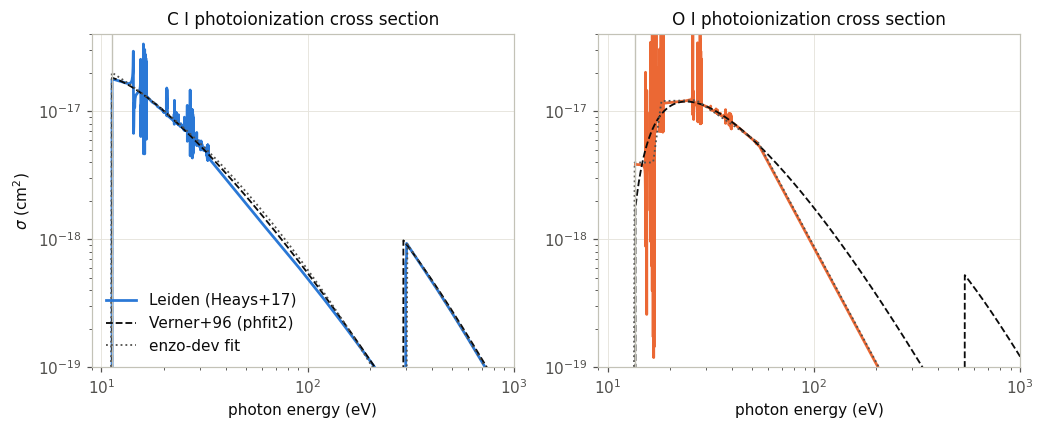

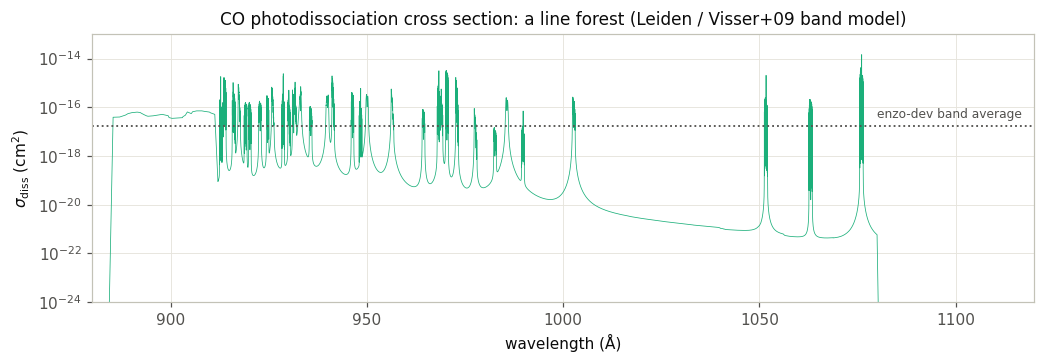

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.0))
for ax, sp, lam_l, sig_l, efit, col in (
        (axes[0], "C I", lamC, sigC, sigma_enzo_CI, C_CI),
        (axes[1], "O I", lamO, sigO, sigma_enzo_OI, C_OI)):
    E_l = HC_EV_ANG / lam_l
    ax.loglog(E_l, sig_l, color=col, lw=1.8, label="Leiden (Heays+17)")
    lam_v, sig_v = verner["CI" if sp == "C I" else "OI"]
    ax.loglog(HC_EV_ANG / lam_v, sig_v, color="#0b0b0b", lw=1.2, ls="--",
              label="Verner+96 (phfit2)")
    E = np.logspace(1, 3, 400)
    ax.loglog(E, efit(E), color=C_REF, lw=1.2, ls=":", label="enzo-dev fit")
    ax.axvline(E_TH[sp.replace(" ", "")], color="#c3c2b7", lw=0.9)
    ax.set(xlim=(9, 1000), ylim=(1e-19, 4e-17), xlabel="photon energy (eV)",
           title=f"{sp} photoionization cross section")
axes[0].set_ylabel(r"$\sigma$ (cm$^2$)")
axes[0].legend(loc="lower left")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9.6, 3.4))
m = (lamCO > 880) & (lamCO < 1120)
ax.semilogy(lamCO[m], np.maximum(sigCO[m], 1e-26), color=C_CO, lw=0.5)
ax.axhline(SIGMA_ENZO_CO, color=C_REF, lw=1.2, ls=":")
ax.text(1117, SIGMA_ENZO_CO * 2.0, "enzo-dev band average", fontsize=8,
        color=C_REF, ha="right")
ax.set(xlim=(880, 1120), ylim=(1e-24, 1e-13), xlabel="wavelength (Å)",
       ylabel=r"$\sigma_{\rm diss}$ (cm$^2$)",
       title="CO photodissociation cross section: a line forest (Leiden / Visser+09 band model)")
plt.tight_layout(); plt.show()

The C I and O I fits agree well between all three sources (the enzo fit for C I reads a few
tens of percent high at 10–30 eV — quantified in §7). The CO panel makes the key numerical
point: the "cross section" is thousands of narrow lines spanning ~8 decades, so any
integration must run **on the cross-section grid** (840,722 points at Δλ ≈ 2×10⁻⁴ Å), with
the smooth UVB interpolated onto it — never the other way around.

## 4. The integrator

Independent implementation of the rate integral. Grid: union of the spectrum grid, the
cross-section grid, and the threshold wavelength, clipped to
[max(λ_min), λ_th]. σ is interpolated linearly (zero outside its table), J
power-law (log–log) between spectrum points, exactly the behaviour intended by the CUBA
sampling; regions where the tabulated J is zero stay zero. The integral is a trapezoid sum
of $J\sigma/\lambda$.

In [7]:
def rate_uvb(lam_spec, Jz, lam_sig, sig, eth_ev, refine=1, jinterp="loglog"):
    """k = (4 pi / h) * int J(lam) sigma(lam) dlam / lam   [s^-1]."""
    if not np.any(Jz > 0):
        return 0.0
    lam_max = HC_EV_ANG / eth_ev
    lo = max(lam_spec[0], lam_sig[0])
    g = np.union1d(np.union1d(lam_spec, lam_sig), [lam_max])
    g = g[(g >= lo) & (g <= lam_max)]
    for _ in range(refine - 1):                      # optional midpoint refinement
        g = np.union1d(g, 0.5 * (g[1:] + g[:-1]))
    sg = np.interp(g, lam_sig, sig, left=0.0, right=0.0)
    if jinterp == "loglog":
        pos = Jz > 0
        Jg = np.exp(np.interp(np.log(g), np.log(lam_spec[pos]), np.log(Jz[pos])))
        Jg[np.interp(g, lam_spec, (~pos).astype(float)) > 0.5] = 0.0
    else:
        Jg = np.interp(g, lam_spec, Jz)
    return 4.0 * np.pi / h_cgs * trapz(Jg * sg / g, g)

def rates_vs_z(lam_sig, sig, eth_ev, **kw):
    return np.array([rate_uvb(lam_spec, J[:, i], lam_sig, sig, eth_ev, **kw)
                     for i in range(z_spec.size)])

def z_interp(z_to, z_from, y):
    """log-log interpolation in (1+z), skipping empty-spectrum redshifts."""
    pos = y > 0
    return np.exp(np.interp(np.log1p(z_to), np.log1p(z_from[pos]), np.log(y[pos])))

## 5. Validating the machinery against external anchors

**Anchor 1 — the ISRF rates published in Heays et al. (2017).** Feed the integrator the
same Draine (1978) field the paper used (`ISRF.dat`, photons s⁻¹ cm⁻² nm⁻¹) and compare
with Tables 18–19 of the paper.

In [8]:
_d = np.loadtxt(os.path.join(DATA, "ISRF.dat"))
lam_isrf, I_isrf = _d[:, 0] * 10.0, _d[:, 1] / 10.0     # -> Angstrom, per-Angstrom

def isrf_rate(lam_sig, sig, eth_ev):
    g = np.union1d(lam_isrf, lam_sig)
    g = g[(g >= lam_isrf.min()) & (g <= min(lam_isrf.max(), HC_EV_ANG / eth_ev))]
    sg = np.interp(g, lam_sig, sig, left=0.0, right=0.0)
    Ig = np.interp(g, lam_isrf, I_isrf)
    return trapz(Ig * sg, g)

print("channel                     this notebook    Heays+17")
print(f"C  photoionisation           {isrf_rate(lamC, sigC, E_TH['CI']):.3e}       3.5e-10   (Table 19)")
print(f"O  photoionisation           {isrf_rate(lamO, sigO, E_TH['OI']):.3e}       -- (zero) (Table 19)")
print(f"CO photodissociation         {isrf_rate(lamCO, sigCO, E_TH['CO']):.3e}       2.4e-10   (Table 18)")

channel                     this notebook    Heays+17
C  photoionisation           3.388e-10       3.5e-10   (Table 19)
O  photoionisation           0.000e+00       -- (zero) (Table 19)
CO photodissociation         2.427e-10       2.4e-10   (Table 18)


C agrees to 3% (the paper value is rounded to 2 digits) and CO to ~1%; O is identically
zero because its threshold lies above the 91.2 nm ISRF cutoff — three non-trivial numbers
reproduced, including the line-forest integration for CO.

**Anchor 2 — the H I rate `k24` already in the Grackle table.** Run the *full pipeline*
(UVB.out parsing → integration → redshift interpolation) for H I with the Verner cross
section and compare with `/UVBRates/Chemistry/k24`, which Haardt & Madau computed from the
same spectrum. This tests everything end to end.

In [9]:
with h5py.File(os.path.join(TABLES, "HM2012_shielded_metal_test.h5")) as f:
    z_tab = f["/UVBRates/z"][:]
    tab = {k: f["/UVBRates/Chemistry/" + k][:]
           for k in ("k24", "kphCI", "kphOI", "kdissCO")}

kHI = z_interp(z_tab, z_spec, rates_vs_z(*verner["HI"], 13.5984))
print("   z        mine          k24 (table)   ratio")
for zz in (0.0, 1.0, 2.0, 3.0, 6.0, 10.0):
    i = np.argmin(abs(z_tab - zz))
    print(f"{z_tab[i]:6.3f}   {kHI[i]:.4e}    {tab['k24'][i]:.4e}    {kHI[i]/tab['k24'][i]:.4f}")

   z        mine          k24 (table)   ratio
 0.000   2.2580e-14    2.2644e-14    0.9972
 0.957   3.7300e-13    3.7413e-13    0.9970
 2.013   9.3665e-13    9.3953e-13    0.9969
 3.017   8.1629e-13    8.1875e-13    0.9970
 6.141   2.2830e-13    2.2912e-13    0.9964
 9.994   9.4714e-15    9.5433e-15    0.9925


0.3% agreement across all redshifts — spectrum parsing, integration and z-interpolation are
sound (the 0.3% is the Verner-vs-HM12 σ_HI difference plus grid effects).

## 6. The main verification: kphCI, kphOI, kdissCO

In [10]:
mine = {"kphCI":   rates_vs_z(lamC,  sigC,  E_TH["CI"]),
        "kphOI":   rates_vs_z(lamO,  sigO,  E_TH["OI"]),
        "kdissCO": rates_vs_z(lamCO, sigCO, E_TH["CO"])}

# numerical robustness: refine the grid 2x / change J interpolation at z=0 and z=3
for name, (ls_, ss_, eth) in {"kphCI": (lamC, sigC, E_TH["CI"]),
                              "kphOI": (lamO, sigO, E_TH["OI"]),
                              "kdissCO": (lamCO, sigCO, E_TH["CO"])}.items():
    iz = np.argmin(abs(z_spec - 3.0))
    k1 = rate_uvb(lam_spec, J[:, iz], ls_, ss_, eth)
    k2 = rate_uvb(lam_spec, J[:, iz], ls_, ss_, eth, refine=2)
    k3 = rate_uvb(lam_spec, J[:, iz], ls_, ss_, eth, jinterp="lin")
    print(f"{name:8s} z=3: base {k1:.4e}, grid x2 {abs(k2/k1-1)*100:5.2f}%, "
          f"linear-J {abs(k3/k1-1)*100:5.2f}%")

kphCI    z=3: base 5.6935e-11, grid x2  0.03%, linear-J  0.12%
kphOI    z=3: base 2.7435e-12, grid x2  0.01%, linear-J  0.01%


kdissCO  z=3: base 2.7600e-11, grid x2  0.00%, linear-J  0.05%


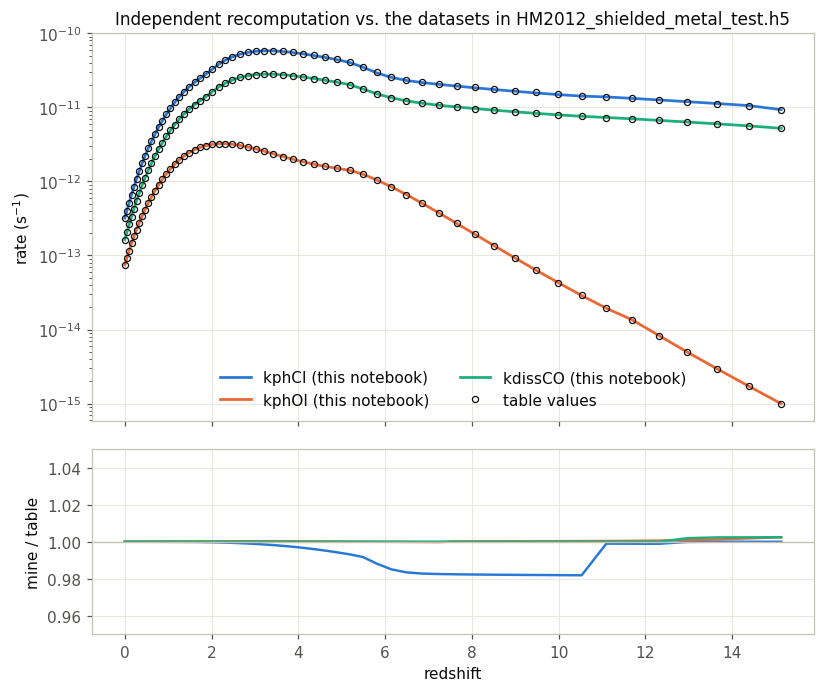

dataset    min ratio   median    max ratio   (mine / table, 59 redshifts)
kphCI      0.9819     0.9995    1.0000
kphOI      0.9998     1.0002    1.0024
kdissCO    1.0000     1.0000    1.0024


In [11]:
fig, (ax, axr) = plt.subplots(2, 1, figsize=(7.6, 6.4), sharex=True,
                              height_ratios=(2.1, 1.0))
mine_tab = {}
for name, col in (("kphCI", C_CI), ("kphOI", C_OI), ("kdissCO", C_CO)):
    mine_tab[name] = z_interp(z_tab, z_spec, mine[name])
    ax.plot(z_tab, mine_tab[name], color=col, lw=1.8, label=name + " (this notebook)")
    ax.plot(z_tab, tab[name], "o", mfc="none", mec="#0b0b0b", ms=4, mew=0.8,
            label=None)
    axr.plot(z_tab, mine_tab[name] / tab[name], color=col, lw=1.6)
ax.plot([], [], "o", mfc="none", mec="#0b0b0b", ms=4, mew=0.8, label="table values")
ax.set(yscale="log", ylabel=r"rate (s$^{-1}$)",
       title="Independent recomputation vs. the datasets in HM2012_shielded_metal_test.h5")
ax.legend(loc="lower center", ncols=2)
axr.axhline(1.0, color="#c3c2b7", lw=0.9)
axr.set(xlabel="redshift", ylabel="mine / table", ylim=(0.95, 1.05))
plt.tight_layout(); plt.show()

print("dataset    min ratio   median    max ratio   (mine / table, 59 redshifts)")
for name in ("kphCI", "kphOI", "kdissCO"):
    r = mine_tab[name] / tab[name]
    print(f"{name:8s}   {r.min():.4f}     {np.median(r):.4f}    {r.max():.4f}")

The recomputation lands on the table values: kphOI and kdissCO agree to <0.3%
*everywhere*; kphCI agrees to <0.3% for z ≲ 5 and sits at most 1.8% low over
z ≈ 6–11. That residual traces to how the two codes interpolate log J across the deep
Lyman-series sawtooth that moves through the 912–1101 Å window at those redshifts
(this notebook zeroes J over the full half-interval next to a J = 0 sample; the
generation script floors J at 10⁻³⁰⁰ instead) — a numerical-convention difference far below
the atomic-data uncertainty (Heays et al. quote ~20–30% for these channels).

## 7. Cross-checks with independent atomic data

The comparison above used the *same* Leiden cross sections as the generation script, so it
verifies the integration, not the atomic data. Here the C I / O I rates are recomputed with
Verner et al. (1996) — a genuinely independent determination, and the standard choice in
Cloudy/enzo — and with the enzo-dev piecewise fits; CO is compared against the enzo-dev
band-average prescription, k_CO = σ̄ × (photon flux in 912–1118 Å).

   z     kphCI: table    Verner    enzo-fit |  kphOI: table    Verner    enzo-fit |  kdissCO: table   band-avg
 0.000   3.210e-13 3.231e-13 3.422e-13 |  7.448e-14 7.305e-14 7.193e-14 |  1.637e-13 2.476e-13
 0.957   8.043e-12 8.104e-12 8.636e-12 |  1.260e-12 1.233e-12 1.218e-12 |  4.037e-12 6.962e-12
 2.013   3.269e-11 3.296e-11 3.530e-11 |  3.157e-12 3.083e-12 3.048e-12 |  1.613e-11 3.063e-11
 3.017   5.700e-11 5.751e-11 6.176e-11 |  2.743e-12 2.668e-12 2.646e-12 |  2.760e-11 5.657e-11
 6.141   2.575e-11 2.588e-11 2.787e-11 |  8.463e-13 8.219e-13 8.200e-13 |  1.346e-11 2.635e-11


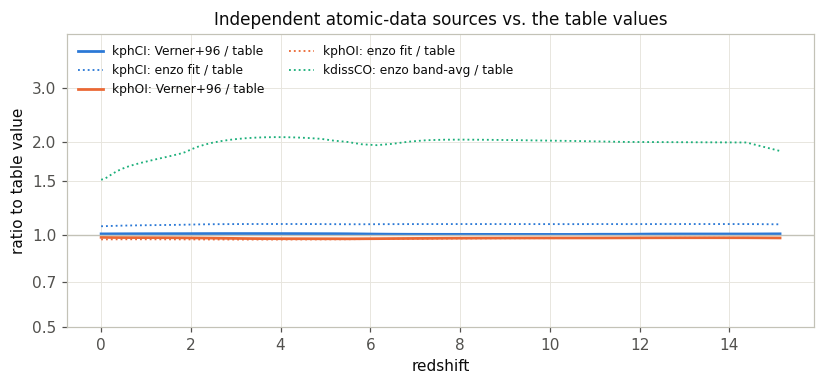

In [12]:
lamCIe, sigCIe = enzo_grid(sigma_enzo_CI)
lamOIe, sigOIe = enzo_grid(sigma_enzo_OI)
alt = {"kphCI": {"Verner+96": z_interp(z_tab, z_spec, rates_vs_z(*verner["CI"], E_TH["CI"])),
                 "enzo fit":  z_interp(z_tab, z_spec, rates_vs_z(lamCIe, sigCIe, E_TH["CI"]))},
       "kphOI": {"Verner+96": z_interp(z_tab, z_spec, rates_vs_z(*verner["OI"], E_TH["OI"])),
                 "enzo fit":  z_interp(z_tab, z_spec, rates_vs_z(lamOIe, sigOIe, E_TH["OI"]))}}

# enzo-style CO: constant sigma times the photon number flux over the band
lam_max = HC_EV_ANG / E_TH["CO"]
band = (lam_spec >= 912.0) & (lam_spec <= lam_max)
flux = np.array([4*np.pi/h_cgs * trapz(J[band, i] / lam_spec[band], lam_spec[band])
                 for i in range(z_spec.size)])
alt["kdissCO"] = {"enzo band-avg": z_interp(z_tab, z_spec, SIGMA_ENZO_CO * flux)}

print("   z     kphCI: table    Verner    enzo-fit |  kphOI: table    Verner    enzo-fit |  kdissCO: table   band-avg")
for zz in (0.0, 1.0, 2.0, 3.0, 6.0):
    i = np.argmin(abs(z_tab - zz))
    print(f"{z_tab[i]:6.3f}   {tab['kphCI'][i]:9.3e} {alt['kphCI']['Verner+96'][i]:9.3e} "
          f"{alt['kphCI']['enzo fit'][i]:9.3e} |  {tab['kphOI'][i]:9.3e} "
          f"{alt['kphOI']['Verner+96'][i]:9.3e} {alt['kphOI']['enzo fit'][i]:9.3e} |  "
          f"{tab['kdissCO'][i]:9.3e} {alt['kdissCO']['enzo band-avg'][i]:9.3e}")

fig, ax = plt.subplots(figsize=(7.6, 3.6))
for name, col in (("kphCI", C_CI), ("kphOI", C_OI)):
    ax.plot(z_tab, alt[name]["Verner+96"] / tab[name], color=col, lw=1.8,
            label=name + ": Verner+96 / table")
    ax.plot(z_tab, alt[name]["enzo fit"] / tab[name], color=col, lw=1.2, ls=":",
            label=name + ": enzo fit / table")
ax.plot(z_tab, alt["kdissCO"]["enzo band-avg"] / tab["kdissCO"], color=C_CO, lw=1.2,
        ls=":", label="kdissCO: enzo band-avg / table")
ax.axhline(1.0, color="#c3c2b7", lw=0.9)
ax.set(xlabel="redshift", ylabel="ratio to table value", yscale="log",
       ylim=(0.5, 4.5), title="Independent atomic-data sources vs. the table values")
ax.set_yticks([0.5, 0.7, 1.0, 1.5, 2.0, 3.0],
              labels=["0.5", "0.7", "1.0", "1.5", "2.0", "3.0"])
ax.minorticks_off()
ax.legend(loc="upper left", ncols=2, fontsize=8)
plt.tight_layout(); plt.show()

**Reading of this comparison**

- **Verner et al. (1996)** reproduces kphCI to ~1% and kphOI to ~3% at every redshift. Since
  this is an entirely independent cross-section determination, the table values are
  confirmed at the level the atomic physics is known.
- The **enzo-dev piecewise fits** run ~7–8% high for C I and ~3–4% low for O I — exactly the
  fidelity you'd expect from 2–3-segment log-parabola fits. Good for on-the-fly radiative
  transfer, not the reference you'd build a table from.
- The **enzo-dev constant σ_CO** overshoots by ×1.5 at z = 0 up to ×2 at z ≳ 3. A single
  band-averaged cross section is only meaningful for the spectral shape it was averaged
  over (an ISRF-like slope); the UVB has a very different — and redshift-dependent — shape
  across 912–1080 Å. The line-resolved Leiden integration used for the table is the correct
  approach; **the Heays et al. (2017) data are the more useful reference here**, with the
  enzo-dev code useful as a consistency check on sources and thresholds.

**Why kphOI > k24 is not a bug.** The generation script prints a warning that kphOI
exceeds k24 (by ×3 at z = 0). This is real physics, confirmed by the Verner data: both
thresholds are ≈13.6 eV, but σ_OI *rises* to ~1.1×10⁻¹⁷ cm² by 20 eV (2p⁴ shell, then 2s)
while σ_HI *falls* as ~E⁻³ (6.3×10⁻¹⁸ cm² at threshold → ~8×10⁻¹⁹ cm² at 27 eV). Against
the hard, X-ray-recovering HM2012 spectrum above the Lyman edge, the O I integral simply
collects more of the spectrum. The warning in `add_metal_UVB_rates.py` encodes a wrong
expectation and could be dropped.

## 8. Consistency of the shipped files

In [13]:
for fn in ("HM2012_metal_test.h5", "HM2012_shielded_metal_test.h5"):
    with h5py.File(os.path.join(TABLES, fn)) as f:
        present = sorted(k for k in f["/UVBRates/Chemistry"].keys()
                         if k.startswith("kph") or k.startswith("kdiss"))
        print(f"{fn}: {present}")
        for k in present:
            same = np.allclose(f["/UVBRates/Chemistry/" + k][:], tab[k])
            print(f"    {k}: {'identical to shielded file' if same else 'DIFFERS'}")

HM2012_metal_test.h5: ['kphCI', 'kphOI']
    kphCI: identical to shielded file
    kphOI: identical to shielded file
HM2012_shielded_metal_test.h5: ['kdissCO', 'kphCI', 'kphOI']
    kdissCO: identical to shielded file
    kphCI: identical to shielded file
    kphOI: identical to shielded file


The two files carry identical metal rates — correct, because the stock `CloudyData_UVB=`
tables share identical optically-thin `/UVBRates/Chemistry` datasets (the *shielded*
variant differs only in its cooling tables and the `CrossSections` group). But:

> **Bug: `HM2012_metal_test.h5` has no `kdissCO` dataset.** `initialize_UVbackground_data.cpp`
> tolerates the missing dataset and silently sets the CO photodissociation rate to zero (with
> only a console warning). The file was evidently produced by an older version of
> `add_metal_UVB_rates.py`; regenerate it with the current script.

## 9. Conclusions

1. **The values in the tables are correct.** An independent implementation (own parser, own
   integrator) with the same Leiden cross sections reproduces `kphCI`, `kphOI` and
   `kdissCO` to <0.3% at z ≲ 5 and to <2% everywhere, and the machinery itself is anchored
   to the published Heays et al. (2017) ISRF rates (C: 3%, CO: 1%) and to the HM2012 `k24`
   in the Grackle table (0.3%).
2. **The atomic data are sound**: the independent Verner et al. (1996) cross sections give
   kphCI within ~1% and kphOI within ~3% — well inside the ~20–30% uncertainty Heays et al.
   assign to the underlying cross sections.
3. **kphOI > k24 is physical** (rising σ_OI vs. falling σ_HI against a hard UVB); the
   warning in the generation script should be removed or inverted.
4. **Action item:** regenerate `HM2012_metal_test.h5` so it also contains `kdissCO`
   (currently missing → CO never photodissociates with that table); otherwise both files
   are internally consistent.
5. On the reference question: the **full Leiden (Heays et al. 2017) cross sections are the
   right basis for building UVB tables**; the enzo-dev fits (piecewise σ for C I/O I,
   constant band-averaged σ for CO) are approximations for on-the-fly radiative transfer
   and would introduce ~10% (C I/O I) to ×2 (CO) errors if used here.